# La escalera de estimadores: de la simulación histórica a GARCH, EVT, CAViaR y GAS-FZ

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema (VaR, ES y un primer conteo de excepciones)
- **Tiempo de lectura:** unos 45 minutos

**Pregunta:** ¿Qué escalones de la escalera de estimadores mantuvieron su conteo de excepciones al 1 por ciento cerca del esperado en seis ventanas de mercado, y qué supone sobre la cola cada escalón de forma cerrada?

## Objetivos

Al terminar este notebook puedes:

- nombrar los escalones de la escalera de estimadores de VaR y ES que Contraste ejecuta, desde la simulación histórica hasta los modelos semiparamétricos dinámicos, y decir qué supone cada uno;
- comprobar sobre un artefacto versionado que cada pronóstico se hizo con información fechada antes de su día y que los hiperparámetros se fijaron antes de las ventanas en que se puntúan;
- ejecutar los escalones de forma cerrada (simulación ponderada por edad, EWMA, delta-normal, Cornish-Fisher, simulación histórica filtrada y la cola por excesos sobre un umbral) sobre retornos reales con las funciones del motor y poner la trayectoria EWMA junto a la versionada;
- decir qué escalones no se pueden reajustar en un notebook y por qué, y leer sus fallas de convergencia en la escalera versionada;
- leer, para seis ventanas de mercado, cuántas veces superó cada escalón su VaR al 1 por ciento y qué escalones retiraron las compuertas de elegibilidad.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con
# notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C11 tal como Contraste lo versiona: un documento por ventana de mercado más el documento de la escalera misma.

- `data/derived/C11/models-ladder.json`: las 18 entradas de la escalera (17 escalones ajustados y un retador que no se ejecutó), cada una con su fuente, innovación, ventana de estimación, frecuencia de reajuste y, por ventana, el número de reajustes, las fallas de convergencia y el rango de sus parámetros ajustados.
- `data/derived/C11/<ventana>.json` para las seis ventanas: `calm-2004-06`, `equity-2007-09`, `equity-2020`, `rates-2022`, `fx-2008` y `mixed-2023`. Cada uno guarda, para cada modelo y nivel de cola, la trayectoria de VaR y ES, los días de excepción y el veredicto de elegibilidad.

Las clases de licencia deciden qué se versiona. De las seis ventanas solo `rates-2022` y `fx-2008` versionan las pérdidas realizadas (datos del Tesoro y H.10 de la Reserva Federal, `mirror-allowed`); las ventanas accionarias y la mixta contienen el retorno de Kenneth French, `derived-only`, así que versionan pronósticos y días de excepción pero no retornos. Los estimadores no se pueden reajustar en una ventana cuyos retornos de estimación no se versionan, y de ninguna ventana se versionan los 1.000 días de estimación. El notebook lee entonces los pronósticos versionados de los escalones ajustados y corre los escalones de forma cerrada sobre los 251 retornos realizados de `fx-2008`, diciendo cada vez qué cambia eso. La celda siguiente carga los siete archivos.

In [2]:
# Cargar el documento de la escalera y los seis documentos de ventana (el notebook está tres carpetas bajo
# la raíz del repositorio)
ROOT = Path("../../..").resolve()
C11 = ROOT / "data" / "derived" / "C11"
ladder_doc = json.loads((C11 / "models-ladder.json").read_text(encoding="utf-8"))
WINDOWS = ("calm-2004-06", "equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "mixed-2023")
windows = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8")) for w in WINDOWS}
ladder = ladder_doc["fit"]["ladder"]
INNOVATION = {"empirical": "empírica", "normal": "normal", "student-t": "t de Student"}
INNOVATION.update({"gpd-tail": "cola GPD", "none": "ninguna"})

print(f"{'model':11s} {'rung':5s} {'innovación':12s} {'días':>5s} {'reajuste':>7s}  estimador")
for entry in ladder:
    days = entry["estimation_window_days"] or "-"
    refit = entry["refit_every_days"] or "-"
    title = entry["title"]["es"]
    innovation = INNOVATION[entry["innovation"]]
    print(f"{entry['model_id']:11s} {entry['rung']:5s} {innovation:12s} {days!s:>5s} {refit!s:>7s}  {title}")
print("riskvalidation", ladder_doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

model       rung  innovación    días reajuste  estimador
hs-250      R1    empírica       250       1  Simulación histórica, 250 días
hs-500      R1    empírica       500       1  Simulación histórica, 500 días
awhs        R2    empírica       250       1  Simulación histórica ponderada por edad
dn-rolling  R3    normal        1000       1  Delta-normal, momentos móviles
cf-rolling  R3    normal        1000       1  VaR de Cornish-Fisher, momentos móviles
ewma        R4    normal        1000       1  EWMA (RiskMetrics)
garch-t     R5    t de Student  1000       1  GARCH(1,1) con innovaciones t de Student
gjr-t       R5    t de Student  1000       1  GJR-GARCH con innovaciones t de Student
egarch-t    R5    t de Student  1000       1  EGARCH con innovaciones t de Student
fhs         R6    empírica      1000       1  Simulación histórica filtrada
evt-mf      R7    cola GPD      1000       1  EVT condicional (McNeil y Frey)
caviar-sav  R8    ninguna       1000       5  CAViaR, valor absol

## Método

### Paso 1: la escalera

Un escalón es una manera de convertir retornos pasados en el VaR y la ES de mañana. La escalera va desde la línea base transparente hasta la frontera académica actual, de modo que un validador pueda preguntar a cualquier escalón complejo si supera al simple que reemplaza. La tabla impresa arriba lista cada escalón con su número (R1 a R10), la distribución que supone para las innovaciones, cuántos días pasados lee y cada cuánto se reajusta. Tres familias importan para lo que sigue: los escalones empíricos (R1, R2 y R6) leen la forma de la cola desde los datos, los normales (R3 y R4) la suponen, y los dinámicos (R5, R8 y R9) dejan que la volatilidad o el propio cuantil se muevan con los datos. La última entrada, `nn-fz`, es un retador neuronal de la literatura que el cálculo **no** entrena; el documento lo dice en vez de omitirlo.

### Paso 2: sin mirar hacia adelante, hiperparámetros fijados de antemano

Dos reglas vuelven honesta una prueba retrospectiva. Primero, cada pronóstico usa solo retornos fechados **antes** de su día: cada documento de ventana registra, para cada fecha de pronóstico, el primer y el último día de la muestra de estimación (`grid.estimation_start`, `grid.estimation_end`). Segundo, los hiperparámetros (el decaimiento de EWMA, el de la ponderación por edad, la fracción del umbral EVT, el número de partidas del optimizador) se eligen sobre un tramo que termina antes de que empiece cada ventana, nunca sobre la ventana que se puntúa (`hyperparameters.fixed_on`, `tuned_on_test_window`). Ambas reglas se pueden verificar en el archivo versionado, lo que hace la celda siguiente con las seis ventanas.

In [3]:
# Comprobar las dos reglas de una prueba retrospectiva honesta en cada ventana: la muestra de estimación
# termina antes de su día
SCHEME = {"rolling": "móvil", "expanding": "creciente"}
print(f"{'window':15s} {'esquema':>22s} {'la muestra termina antes de su día':>8s} {'hiperparámetros fijados en'}")
for w, doc in windows.items():
    grid, hyper = doc["outputs"]["grid"], doc["outputs"]["hyperparameters"]
    before = all(end < day for end, day in zip(grid["estimation_end"], grid["dates"]))
    fixed = hyper["fixed_on"]
    print(f"{w:15s} {SCHEME[grid['scheme']]} {grid['estimation_window_days']:>5d} | {'sí' if before else 'no'} | "
          f"{fixed['start']} a {fixed['end']} | ajustado en la ventana de prueba: "
          f"{'sí' if hyper['tuned_on_test_window'] else 'no'}")

window                         esquema la muestra termina antes de su día hiperparámetros fijados en
calm-2004-06    móvil  1000 | sí | 1995-01-01 a 2003-12-31 | ajustado en la ventana de prueba: no
equity-2007-09  móvil  1000 | sí | 1995-01-01 a 2003-12-31 | ajustado en la ventana de prueba: no
equity-2020     móvil  1000 | sí | 1995-01-01 a 2003-12-31 | ajustado en la ventana de prueba: no
rates-2022      móvil  1000 | sí | 1995-01-01 a 2003-12-31 | ajustado en la ventana de prueba: no
fx-2008         móvil  1000 | sí | 1995-01-01 a 2003-12-31 | ajustado en la ventana de prueba: no
mixed-2023      móvil  1000 | sí | 1995-01-01 a 2003-12-31 | ajustado en la ventana de prueba: no


### Paso 3: simulación histórica ponderada por edad (escalón R2)

La simulación histórica simple da el mismo peso a cada día de la ventana, de modo que un día de crisis sale de la ventana de una vez y el VaR salta. Boudoukh, Richardson y Whitelaw (1998) ponderan el retorno observado hace $i$ días por

$$w_i = \frac{1-\lambda}{1-\lambda^{K}}\,\lambda^{\,i-1}, \qquad i = 1,\dots,K$$

ordenan los retornos, acumulan los pesos hasta alcanzar $\alpha$ e interpolan. La función `age_weights(lam, k)` del motor devuelve los pesos y `age_weighted_var_es(returns, alpha, lam, window)` el pronóstico; la ES es la integral de cola de la misma función cuantil interpolada (el artículo no da regla para la ES, el motor documenta esto como su decisión D-9). Usamos el $\lambda$ versionado y los primeros 100 retornos de `fx-2008`, una ventana más corta que el $K = 250$ versionado, y comparamos con el pronóstico de pesos iguales al nivel de 2,5 por ciento, donde la cola contiene 2,5 observaciones.

lambda 0.99, K 100: más reciente 0.01577 | más antiguo 0.00583
días efectivos 1 / sum(w^2): 92.4
alfa 0.01: iguales VaR 0.022293 ES 0.022293 | edad VaR 0.022072 ES 0.022246
alfa 0.025: iguales VaR 0.020861 ES 0.021771 | edad VaR 0.021324 ES 0.021933


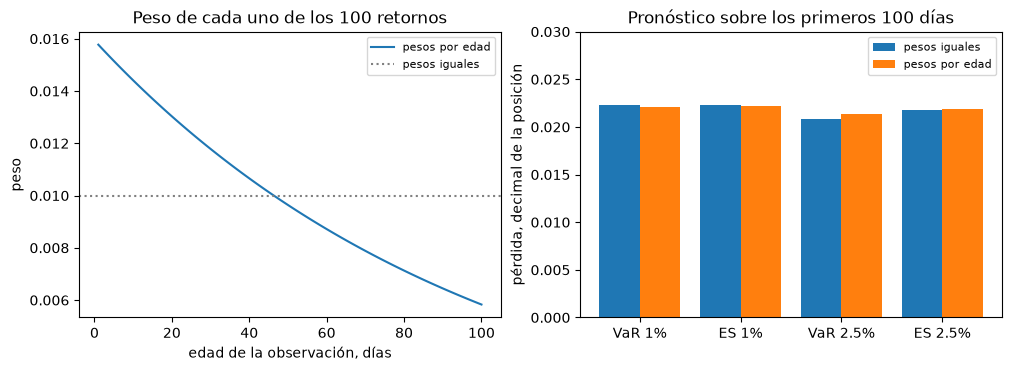

In [4]:
# Pesos por edad con la caída versionada y pronóstico ponderado por edad frente al de pesos iguales sobre
# 100 retornos
from riskvalidation.market.historical import age_weighted_var_es, age_weights, historical_var_es

fx_out = windows["fx-2008"]["outputs"]
y = -np.array(fx_out["grid"]["realised_loss"]["loss"])
lam_age = fx_out["hyperparameters"]["age_weight_lambda"]
K = 100
weights = age_weights(lam_age, K)
print(f"lambda {lam_age}, K {K}: más reciente {weights[0]:.5f} | más antiguo {weights[-1]:.5f}")
print(f"días efectivos 1 / sum(w^2): {1 / np.sum(weights ** 2):.1f}")

values = {"equal": [], "aged": []}
for alpha in (0.01, 0.025):
    equal = historical_var_es(y[:K], alpha, K)
    aged = age_weighted_var_es(y[:K], alpha, lam_age, K)
    values["equal"] += [-equal[0], -equal[1]]
    values["aged"] += [-aged[0], -aged[1]]
    print(f"alfa {alpha}: iguales VaR {-equal[0]:.6f} ES {-equal[1]:.6f} | edad VaR {-aged[0]:.6f} ES {-aged[1]:.6f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
left.plot(np.arange(1, K + 1), weights, label="pesos por edad")
left.axhline(1 / K, color="grey", linestyle=":", label="pesos iguales")
left.set_xlabel("edad de la observación, días")
left.set_ylabel("peso")
left.set_title("Peso de cada uno de los 100 retornos")
left.legend(fontsize=8)
for shift, (name, label) in zip((-0.2, 0.2), (("equal", "pesos iguales"), ("aged", "pesos por edad"))):
    right.bar(np.arange(4) + shift, values[name], width=0.4, label=label)
right.set_xticks(np.arange(4), ["VaR 1%", "ES 1%", "VaR 2.5%", "ES 2.5%"])
right.set_ylim(0, 0.03)
right.set_ylabel("pérdida, decimal de la posición")
right.set_title("Pronóstico sobre los primeros 100 días")
right.legend(fontsize=8)
plt.show()

El panel izquierdo muestra el peso de cada uno de los 100 retornos, desde 0,01577 para el más reciente hasta 0,00583 para el más antiguo, frente al 0,010 de los pesos iguales; el número efectivo de días es 92,4 de 100, de modo que la caída cambia poco en una ventana tan corta. El panel derecho muestra dónde sí importa la elección de pesos: al nivel de 1 por ciento el VaR y la ES con pesos iguales son ambos 0,022293, porque la cola contiene una sola observación, mientras que la ponderación por edad reparte la cola en dos retornos y da una ES de 0,022246 algo sobre su VaR de 0,022072. A 2,5 por ciento sube el VaR de 0,020861 a 0,021324. La figura no muestra que ponderar por edad sea mejor, solo que mueve la estimación de la cola cerca de un dos por ciento aquí; si ayuda es una pregunta para los conteos de excepciones de la última figura.

### Paso 4: EWMA, la volatilidad que reacciona (escalón R4)

RiskMetrics modela la varianza del retorno de mañana como un promedio exponencial de los retornos al cuadrado, con media cero (la media cero es parte del método):

$$\sigma^2_{t+1\mid t} = \lambda\,\sigma^2_{t\mid t-1} + (1-\lambda)\,r_t^2, \qquad K = \frac{\ln \varepsilon}{\ln \lambda}$$

donde $K$ es el número de días que llevan un peso sobre la tolerancia $\varepsilon$ (RiskMetrics Technical Document, sección 5.3.2). El VaR y la ES salen entonces de la distribución normal con esa varianza (delta-normal, escalón R3):

$$v = \mu + \Phi^{-1}(\alpha)\,\sigma, \qquad e = \mu - \sigma\,\frac{\varphi(\Phi^{-1}(\alpha))}{\alpha}$$

La celda ejecuta `ewma_variance` del motor sobre los 251 retornos realizados con la caída $\lambda$ versionada, partiendo de la varianza de los primeros 20 retornos, convierte cada volatilidad pronosticada en un VaR al 1 por ciento con `delta_normal_var_es` y cuenta cuántas veces se superó ese VaR. La figura pone la trayectoria recalculada junto al VaR de `ewma` versionado y al de `hs-250` versionado.

lambda 0.97 | días con un peso sobre 1%: 151.2
sigma: primer día 0.004846 | último día 0.008828 | máximo 0.014615
excepciones del VaR al 1%: 3 | esperadas 2.51


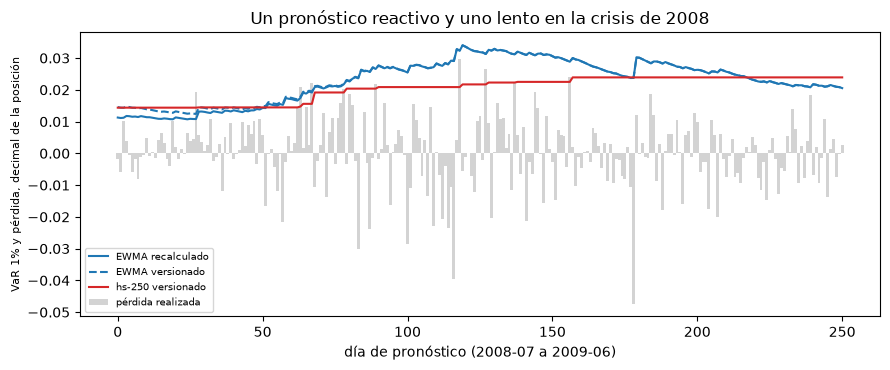

In [5]:
# Volatilidad EWMA del motor, partiendo de los primeros 20 retornos, el VaR delta-normal al 1% que implica y
# sus excepciones
from riskvalidation.market.parametric import delta_normal_var_es, ewma_effective_days, ewma_variance

lam = fx_out["hyperparameters"]["ewma_lambda"]
sigma = np.sqrt(ewma_variance(y[:-1], lam, float(np.var(y[:20]))))
var_ewma = np.array([-delta_normal_var_es(0.0, s, 0.01)[0] for s in sigma])
loss = -y
print(f"lambda {lam} | días con un peso sobre 1%: {ewma_effective_days(lam, 0.01):.1f}")
print(f"sigma: primer día {sigma[0]:.6f} | último día {sigma[-1]:.6f} | máximo {sigma.max():.6f}")
print(f"excepciones del VaR al 1%: {int((loss > var_ewma).sum())} | esperadas {0.01 * y.size:.2f}")

models = {m["model_id"]: m for m in fx_out["models"]}
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(np.arange(y.size), loss, color="lightgrey", width=1.0, label="pérdida realizada")
ax.plot(var_ewma, color="tab:blue", label="EWMA recalculado")
ax.plot(models["ewma"]["by_level"][0]["var"], color="tab:blue", linestyle="--", label="EWMA versionado")
ax.plot(models["hs-250"]["by_level"][0]["var"], color="tab:red", label="hs-250 versionado")
ax.set_xlabel("día de pronóstico (2008-07 a 2009-06)")
ax.set_ylabel("VaR 1% y pérdida, decimal de la posición", fontsize=8)
ax.set_title("Un pronóstico reactivo y uno lento en la crisis de 2008")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

La trayectoria EWMA recalculada (azul continuo) parte bajo la versionada (discontinua) porque su varianza inicial sale de solo 20 retornos, y se une a la versionada en unos 30 días; desde entonces las dos líneas son indistinguibles, así que el escalón versionado y la función del motor describen la misma recursión. La volatilidad pronosticada sube de 0,004846 el primer día a un máximo de 0,014615 y el VaR la sigue hasta cerca de 0,034, mientras que el VaR de `hs-250` versionado (rojo) se queda cerca de 0,015 durante dos meses y luego se mueve a saltos, uno por cada excepción. EWMA cuenta 3 excepciones de su VaR al 1 por ciento contra 2,51 esperadas. La figura no muestra el costo de la reactividad: después del máximo el VaR de EWMA baja, y con una caída de 0,97 el pronóstico olvida una crisis en unos 151,2 días.

### Paso 5: Cornish-Fisher (escalón R3)

El escalón delta-normal subcubre cuando los retornos tienen colas gruesas o asimetría. La expansión de Cornish-Fisher corrige el cuantil normal $z = \Phi^{-1}(\alpha)$ con la asimetría $S$ y el exceso de curtosis $K_e$ de los retornos:

$$z_{CF} = z + \frac{(z^2-1)S}{6} + \frac{(z^3-3z)K_e}{24} - \frac{(2z^3-5z)S^2}{36}, \qquad v = \mu + z_{CF}\,\sigma$$

La expansión no es monótona para $S$ y $K_e$ grandes, así que un pronóstico debe informar si está en su dominio de validez; la función `cornish_fisher_var` del motor devuelve `valid`. Da un VaR y ninguna ES, por lo que el `cf-rolling` versionado no tiene puntaje FZ0 (notebook 05). Comparamos las tres estimaciones de VaR sobre los momentos muestrales de los 251 retornos.

media -0.000407 | desviación estándar 0.010608 | asimetría 0.629 | curtosis en exceso 2.129
alfa 0.01: z -2.326 -> z_CF -2.212 | expansión válida: sí
  VaR normal 0.025085 | Cornish-Fisher 0.023873 | empírico 0.023915
alfa 0.025: z -1.960 -> z_CF -1.750 | expansión válida: sí
  VaR normal 0.021198 | Cornish-Fisher 0.018974 | empírico 0.020861


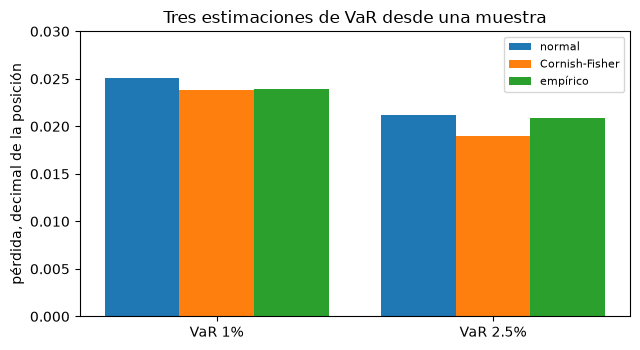

In [6]:
# VaR de Cornish-Fisher desde los momentos muestrales frente al delta-normal y al cuantil empírico, en los
# dos niveles
from riskvalidation.market.conventions import var_es_from_sample
from riskvalidation.market.parametric import cornish_fisher_var

mu, sd = float(y.mean()), float(y.std())
skew, excess = float(stats.skew(y)), float(stats.kurtosis(y))
print(f"media {mu:.6f} | desviación estándar {sd:.6f} | asimetría {skew:.3f} | "
      f"curtosis en exceso {excess:.3f}")
estimates = []
for alpha in (0.01, 0.025):
    cf = cornish_fisher_var(mu, sd, skew, excess, alpha)
    normal = delta_normal_var_es(mu, sd, alpha)
    empirical = var_es_from_sample(y, alpha)
    estimates.append((-normal[0], -cf.var, -empirical[0]))
    print(f"alfa {alpha}: z {stats.norm.ppf(alpha):.3f} -> z_CF {cf.z_cf:.3f} | expansión válida: "
          f"{'sí' if cf.valid else 'no'}")
    print(f"  VaR normal {-normal[0]:.6f} | Cornish-Fisher {-cf.var:.6f} | empírico {-empirical[0]:.6f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for k, name in enumerate(("normal", "Cornish-Fisher", "empírico")):
    ax.bar(np.arange(2) + (k - 1) * 0.27, [row[k] for row in estimates], width=0.27, label=name)
ax.set_xticks(np.arange(2))
ax.set_xticklabels(["VaR 1%", "VaR 2.5%"])
ax.set_ylim(0, 0.03)
ax.set_ylabel("pérdida, decimal de la posición")
ax.set_title("Tres estimaciones de VaR desde una muestra")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Los retornos tienen asimetría positiva (0,629) y una curtosis en exceso de 2,129, de modo que sus colas son más pesadas que las de la normal aunque la asimetría favorezca a la posición larga. La corrección de Cornish-Fisher responde achicando el cuantil de pérdida: al 1 por ciento lleva el VaR normal de 0,025085 a 0,023873, casi exactamente el empírico 0,023915, y al 2,5 por ciento se pasa, 0,018974 frente a un empírico de 0,020861 y un normal de 0,021198. La expansión fue válida en los dos niveles. La figura muestra un ajuste de momentos que coincide en un nivel y falla en el otro; es una corrección de la normal, no un modelo mejor de la cola, y con 251 días la asimetría y la curtosis de las que se alimenta son a su vez ruidosas.

### Paso 6: simulación histórica filtrada y cola por excesos sobre un umbral (escalones R6 y R7)

Los dos escalones primero **filtran** los retornos, dividiendo cada uno por la volatilidad pronosticada antes de él, $z_t = r_t/\sigma_t$, de modo que los residuos estandarizados sean casi idénticamente distribuidos. La simulación histórica filtrada (Barone-Adesi, Giannopoulos y Vosper, 1999) reescala luego esos residuos con la volatilidad de mañana, $r^*_s = \mu_{T+1} + \sigma_{T+1} z_s$, y lee el VaR y la ES de los escenarios. La EVT condicional (McNeil y Frey, 2000) ajusta en cambio una distribución de Pareto generalizada a los excesos de los residuos de pérdida $-z_t$ sobre un umbral $u$ (el cuantil $1-f$) y extrapola; con $N_u$ excedencias de $n$ y $q = 1-\alpha$,

$$\hat z_q = u + \frac{\hat\beta}{\hat\xi}\left[\left(\tfrac{n}{N_u}(1-q)\right)^{-\hat\xi} - 1\right], \qquad \widehat{\mathrm{ES}}_q = \frac{\hat z_q}{1-\hat\xi} + \frac{\hat\beta - \hat\xi u}{1-\hat\xi} \quad (\hat\xi<1)$$

Los escalones versionados filtran con un modelo GARCH ajustado sobre 1.000 días de estimación que no se versionan, así que no se pueden reajustar aquí. El filtro de esta celda es la volatilidad EWMA del paso 4, que ejercita las mismas funciones del motor (`filtered_hs_var_es`, `fit_gpd`, `evt_var_es`) sobre residuos reales; los números son los de un escalón filtrado con EWMA sobre 251 días, no los de `fhs` ni `evt-mf` versionados. La celda estandariza los retornos, ajusta la cola con la fracción de umbral versionada e imprime el VaR y la ES del día siguiente de los tres estimadores.

In [7]:
# Estandarizar los retornos con la volatilidad EWMA, ajustar la cola GPD y pronosticar el día siguiente con
# tres estimadores
from riskvalidation.market.evt import evt_var_es, fit_gpd
from riskvalidation.market.historical import filtered_hs_var_es

residuals = y / sigma
fraction = fx_out["hyperparameters"]["evt_threshold_fraction"]
tail = fit_gpd(-residuals, fraction)
print(f"residuos estandarizados: media {residuals.mean():.3f} | "
      f"desviación estándar {residuals.std():.3f} | mínimo {residuals.min():.3f}")
print(f"GPD fracción de umbral {fraction}: u {tail.threshold:.3f}, xi {tail.xi:.3f}, beta {tail.beta:.3f}, "
      f"{tail.n_exceed} excedencias de {tail.n}")
for alpha in (0.01, 0.025):
    fhs = filtered_hs_var_es(residuals, 0.0, sigma[-1], alpha)
    z_q, es_q = evt_var_es(tail, 1.0 - alpha)
    normal = delta_normal_var_es(0.0, sigma[-1], alpha)
    print(f"alfa {alpha}: VaR (ES) | normal {-normal[0]:.5f} ({-normal[1]:.5f}) | "
          f"SH filtrada {-fhs[0]:.5f} ({-fhs[1]:.5f}) | EVT {sigma[-1] * z_q:.5f} ({sigma[-1] * es_q:.5f})")

residuos estandarizados: media -0.077 | desviación estándar 1.105 | mínimo -4.127
GPD fracción de umbral 0.05: u 1.904, xi 0.474, beta 0.235, 13 excedencias de 251
alfa 0.01: VaR (ES) | normal 0.02054 (0.02353) | SH filtrada 0.02389 (0.02918) | EVT 0.02198 (0.03060)
alfa 0.025: VaR (ES) | normal 0.01730 (0.02064) | SH filtrada 0.01859 (0.02349) | EVT 0.01861 (0.02420)


La forma $\hat\xi$ de la cola es el número del que depende un pronóstico EVT, y depende de la fracción de umbral que elija el validador. La celda siguiente reajusta la cola con cinco fracciones usando `threshold_stability` del motor y dibuja la forma y el número de excedencias en que se apoya.

fracción de umbral 0.04 | xi   0.513 | excedencias 10
fracción de umbral 0.05 | xi   0.474 | excedencias 13
fracción de umbral 0.06 | xi   0.202 | excedencias 15
fracción de umbral 0.08 | xi   0.135 | excedencias 20
fracción de umbral 0.10 | xi  -0.036 | excedencias 25


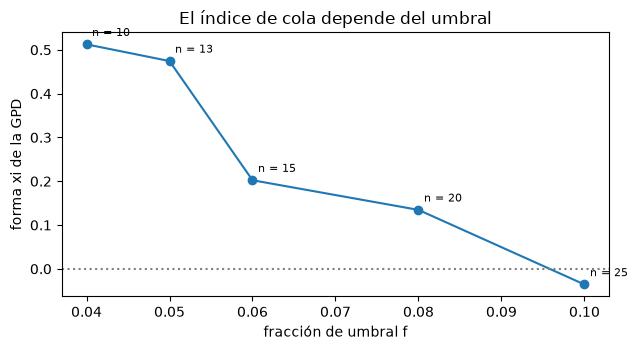

In [8]:
# Reajustar la cola GPD con cinco fracciones de umbral y dibujar la forma con las excedencias en que se apoya
from riskvalidation.market.evt import threshold_stability

table = threshold_stability(-residuals, np.array([0.04, 0.05, 0.06, 0.08, 0.10]))
for fraction_i, xi, n_exceed in table:
    print(f"fracción de umbral {fraction_i:.2f} | xi {xi:7.3f} | excedencias {n_exceed}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot([row[0] for row in table], [row[1] for row in table], marker="o")
for fraction_i, xi, n_exceed in table:
    ax.annotate(f"n = {n_exceed}", (fraction_i, xi), textcoords="offset points", xytext=(4, 6), fontsize=8)
ax.axhline(0, color="grey", linestyle=":")
ax.set_xlabel("fracción de umbral f")
ax.set_ylabel("forma xi de la GPD")
ax.set_title("El índice de cola depende del umbral")
fig.tight_layout()
plt.show()

La forma va de 0,513 con 10 excedencias a -0,036 con 25, de modo que el índice de cola cambia de signo dentro del rango de umbrales que un profesional probaría, y con 251 días un umbral de 5 por ciento deja 13 excedencias. Una forma positiva significa una cola pesada sin cota superior para la pérdida y una negativa una cola acotada, así que la elección del umbral decide qué historia cuenta el pronóstico. La tabla de arriba muestra la consecuencia para el pronóstico: el VaR al 1 por ciento del día siguiente es 0,02054 con la normal, 0,02389 con la simulación histórica filtrada y 0,02198 con EVT, pero la ES es 0,02353, 0,02918 y 0,03060, una dispersión de 30 por ciento entre la más baja y la más alta. La ES es donde importa el modelo de la cola, y la fracción de umbral es un hiperparámetro que el validador debe fijar antes de la ventana, como comprobó el paso 2.

### Paso 7: los escalones que no se pueden reajustar aquí, y cómo se comportaron sus ajustes

Tres familias necesitan más de lo que un notebook puede reproducir desde archivos versionados, y el documento de la escalera es la evidencia sobre ellas.

- **Familia GARCH (R5):** $\sigma_t^2 = \omega + \alpha_1\varepsilon_{t-1}^2 + \beta_1\sigma_{t-1}^2$ (Bollerslev, 1986), con un término de apalancamiento $\gamma\,\mathbb 1\{\varepsilon_{t-1}<0\}\varepsilon_{t-1}^2$ en GJR (Glosten, Jagannathan y Runkle, 1993) y $\ln\sigma_t^2 = \omega + \beta\ln\sigma_{t-1}^2 + \theta z_{t-1} + \gamma(|z_{t-1}| - E|z|)$ en EGARCH (Nelson, 1991), todos con innovaciones t de Student. El motor los ajusta mediante el paquete opcional `arch`.
- **CAViaR (R8):** el propio VaR sigue una recursión, por ejemplo $f_t = b_1 + b_2 f_{t-1} + b_3 |y_{t-1}|$ (Engle y Manganelli, 2004), ajustada minimizando la pérdida de cuantil desde varios puntos de partida; `caviar-es` agrega una brecha autorregresiva bajo el VaR (Taylor, 2019), estimada en dos pasos, una desviación declarada de la estimación conjunta de Taylor. `fit_caviar` del motor exige al menos 500 retornos.
- **GAS-FZ (R9):** el par (VaR, ES) sigue una recursión guiada por el gradiente, ajustada minimizando la pérdida FZ0 promedio (Patton, Ziegel y Chen, 2019); `fit_gas_fz` también exige al menos 500 retornos. El notebook 07 vuelve sobre ellos.

Ninguna ventana versiona 500 retornos de estimación, así que el notebook no los reajusta. Lo que la escalera registra es cómo se comportaron los ajustes: el número de reajustes y de fallas de convergencia por escalón y ventana. La figura muestra la proporción de reajustes que no convergieron en los escalones que se ajustan por optimización.

mayor proporción: garch-t en mixed-2023, 73.4%
parámetros medianos equity-2007-09, garch-t: {'alpha[1]': 0.0596, 'beta[1]': 0.9195, 'mu': 0.0007, 'nu': 8.4689, 'omega': 0.0}
parámetros medianos equity-2007-09, gjr-t: {'alpha[1]': 0.0, 'beta[1]': 0.9207, 'gamma[1]': 0.1167, 'mu': 0.0004, 'nu': 9.0724, 'omega': 0.0}
parámetros medianos equity-2007-09, egarch-t: {'alpha[1]': 0.045, 'beta[1]': 0.9801, 'gamma[1]': -0.1529, 'mu': 0.0004, 'nu': 8.4864, 'omega': -0.1956}


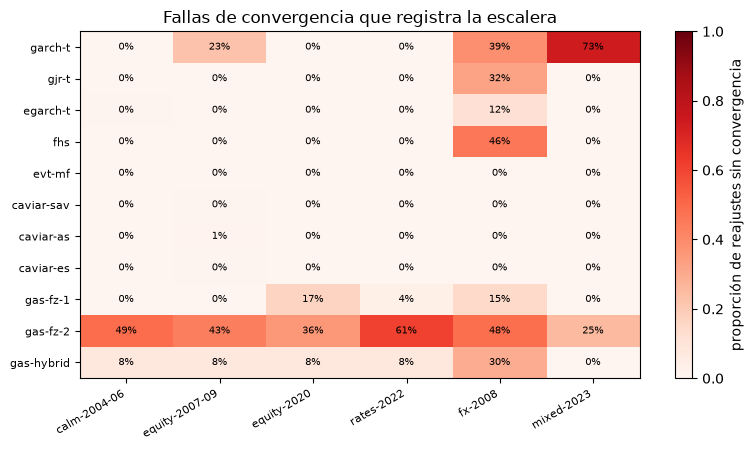

In [9]:
# Proporción de reajustes sin convergencia, por escalón y ventana, como mapa de calor, y los parámetros
# medianos de GARCH
fits = {e["model_id"]: {wf["window_id"]: wf for wf in e["window_fits"]} for e in ladder if e["window_fits"]}
fitted = ["garch-t", "gjr-t", "egarch-t", "fhs", "evt-mf", "caviar-sav", "caviar-as", "caviar-es"]
fitted += ["gas-fz-1", "gas-fz-2", "gas-hybrid"]
share = np.array([[fits[m][w]["n_convergence_failures"] / fits[m][w]["n_refits"] for w in WINDOWS] for m in fitted])
worst = np.unravel_index(share.argmax(), share.shape)
print(f"mayor proporción: {fitted[worst[0]]} en {WINDOWS[worst[1]]}, {share.max():.1%}")
for m in ("garch-t", "gjr-t", "egarch-t"):
    params = {p["name"]: round(p["median"], 4) for p in fits[m]["equity-2007-09"]["parameters"]}
    print(f"parámetros medianos equity-2007-09, {m}: {params}")

fig, ax = plt.subplots(figsize=(8, 4.6))
image = ax.imshow(share, cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(WINDOWS)))
ax.set_xticklabels(WINDOWS, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(fitted)))
ax.set_yticklabels(fitted, fontsize=8)
for i in range(len(fitted)):
    for j in range(len(WINDOWS)):
        ax.text(j, i, f"{share[i, j]:.0%}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="proporción de reajustes sin convergencia")
ax.set_title("Fallas de convergencia que registra la escalera")
fig.tight_layout()
plt.show()

La celda más oscura es GARCH-t en `mixed-2023`, donde 73,4 por ciento de los reajustes no convergió, y toda la fila de `gas-fz-2` está sombreada: entre un cuarto y 61 por ciento de sus ajustes fallan en cada ventana. CAViaR y el escalón EVT casi nunca fallan (0 a 1 por ciento), y la simulación histórica filtrada hereda las fallas del filtro GARCH sobre el que corre, 46 por ciento en `fx-2008`. Los parámetros medianos de la crisis accionaria (GARCH-t alfa 0,0596, beta 0,9195, nu 8,4689) describen un proceso persistente y de colas pesadas, pero una mediana tomada sobre ajustes que incluyen fallidos es tan confiable como la proporción de fallas que la acompaña. La figura registra cómo se comportó el optimizador; no dice qué hizo el proceso con un reajuste fallido, y por eso estos escalones se juzgan por sus pronósticos y no por sus ajustes.

### Paso 8: la escalera completa frente a seis ventanas

La tabla final pone el conteo de excepciones al 1 por ciento de cada escalón junto al conteo esperado de la binomial, en cada ventana, y marca los escalones que sacaron las compuertas de elegibilidad (Kupiec, cobertura condicional o la prueba de Acerbi-Szekely en rojo en cualquiera de los dos niveles; las compuertas son el tema de los notebooks 03 y 04). Una razón cercana a 1 es un pronóstico del tamaño correcto; una razón muy superior a 1 subcubre. El mapa de calor dibuja las mismas razones. `mixed-2023` espera solo 0,6 excepciones en 64 días, así que cada escalón tiene un conteo de 0 y la ventana no puede separar los escalones por cobertura.

excepciones esperadas por ventana: [7.5, 5.0, 1.0, 2.5, 2.5, 0.6]
escalones retirados por las compuertas por ventana: [6, 17, 13, 13, 7, 0] de 17
equity-2007-09: rango de conteos 13 a 57


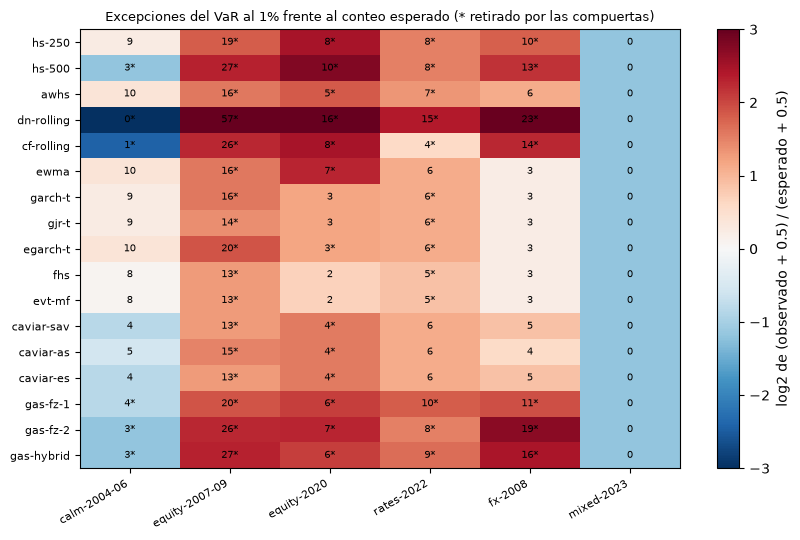

In [10]:
# Excepciones del VaR al 1% frente al conteo esperado para cada escalón y ventana, como mapa de calor de la
# razón
rungs = [m["model_id"] for m in windows["fx-2008"]["outputs"]["models"]]
counts = np.zeros((len(rungs), len(WINDOWS)))
expected = np.zeros(len(WINDOWS))
removed = np.zeros((len(rungs), len(WINDOWS)), dtype=bool)
for j, w in enumerate(WINDOWS):
    for i, model in enumerate(windows[w]["outputs"]["models"]):
        level = model["by_level"][0]
        counts[i, j], expected[j] = level["n_exceedances"], level["expected_exceedances"]
        removed[i, j] = not model["eligible"]
print("excepciones esperadas por ventana:", expected.round(1).tolist())
print("escalones retirados por las compuertas por ventana:", removed.sum(axis=0).tolist(), "de", len(rungs))
print("equity-2007-09: rango de conteos", int(counts[:, 1].min()), "a", int(counts[:, 1].max()))

ratio = (counts + 0.5) / (expected + 0.5)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
image = ax.imshow(np.log2(ratio), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(len(WINDOWS)))
ax.set_xticklabels(WINDOWS, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(rungs)))
ax.set_yticklabels(rungs, fontsize=8)
for i in range(len(rungs)):
    for j in range(len(WINDOWS)):
        ax.text(j, i, f"{int(counts[i, j])}{'*' if removed[i, j] else ''}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="log2 de (observado + 0.5) / (esperado + 0.5)")
ax.set_title("Excepciones del VaR al 1% frente al conteo esperado (* retirado por las compuertas)", fontsize=9)
fig.tight_layout()
plt.show()

Las celdas rojas superan el conteo esperado, las azules quedan bajo él, y una estrella marca un escalón que las compuertas retiraron. En `equity-2007-09` todos los escalones son rojos y llevan estrella, con 13 a 57 excepciones frente a 5,0 esperadas. En la ventana tranquila los retiros van en sentido contrario: `dn-rolling` tiene 0 excepciones contra 7,5 y los escalones GAS-FZ 3 a 4, de modo que las compuertas también detectan pronósticos demasiado cautelosos. En `fx-2008` EWMA, los tres GARCH, la simulación histórica filtrada y EVT quedan en 3 excepciones contra 2,5 esperadas y sobreviven, mientras que los tres escalones GAS-FZ tienen 11, 19 y 16. En `mixed-2023` ningún escalón tiene una excepción en 64 días (0,6 esperadas), así que esa columna no puede separar los escalones por cobertura. En las cinco ventanas donde un conteo puede separarlos ningún escalón pasa las compuertas en todas, y los mejores las pasan en tres.

## Resultados

**Respuesta:** Ningún escalón mantuvo su conteo cerca del esperado en todas las ventanas. Las compuertas de elegibilidad retiraron 6, 17, 13, 13, 7 y 0 de los 17 escalones en las seis ventanas; en `equity-2007-09` los conteos fueron de 13 a 57 excepciones frente a 5,0 esperadas, y los escalones que mejor lo hicieron en otras ventanas (EWMA, las variantes de CAViaR, GARCH-t, la simulación histórica filtrada y EVT) pasaron las compuertas en solo tres de las cinco ventanas donde un conteo puede separarlos.

- **La escalera.** Tiene 18 entradas: 17 escalones ajustados desde la simulación histórica (R1) hasta los modelos GAS-FZ (R9), y `nn-fz` (R10), un retador neuronal que el cálculo registra como no ejecutado. Nada en los datos versionados dice que se evaluó un modelo neuronal.
- **Sin mirar hacia adelante.** En las seis ventanas cada muestra de estimación termina antes de su día de pronóstico, y los hiperparámetros se fijaron en 1995-01-01 a 2003-12-31, antes de todas las ventanas, sin usar nunca la ventana de prueba para ajustarlos.
- **Ponderación por edad y la cola.** Con una caída de 0,99 y 100 días el número efectivo de días es 92,4. A 2,5 por ciento el pronóstico con pesos iguales es 0,020861 para el VaR y 0,021771 para la ES, el ponderado por edad 0,021324 y 0,021933. A 1 por ciento la cola es una observación, así que con pesos iguales la ES es igual al VaR (0,022293 las dos): una ES necesita una cola con varias observaciones.
- **EWMA reacciona.** Con una caída de 0,97 el peso baja de 1 por ciento tras 151,2 días. La volatilidad sube de 0,004846 a 0,014615 en la crisis, y el VaR de EWMA tiene 3 excepciones contra 2,51 esperadas, algo que una ventana fija de 250 días no podía lograr.
- **Normal, Cornish-Fisher y la muestra.** Los retornos tienen una asimetría de 0,629 y una curtosis en exceso de 2,129. Al 1 por ciento el VaR es 0,025085 con la normal, 0,023873 con Cornish-Fisher y 0,023915 empíricamente; al 2,5 por ciento 0,021198, 0,018974 y 0,020861. La corrección ayuda en un nivel y se pasa en el otro.
- **Simulación filtrada y EVT sobre residuos EWMA.** Los residuos estandarizados tienen una desviación estándar de 1,105 y un mínimo de -4,127. Al 1 por ciento el VaR (ES) del día siguiente es 0,02054 (0,02353) normal, 0,02389 (0,02918) simulación histórica filtrada y 0,02198 (0,03060) EVT. La forma de la GPD depende del umbral, 0,513 con 10 excedencias y -0,036 con 25, de modo que el índice de cola cambia de signo dentro del rango que un profesional probaría.
- **Los ajustes que no se pueden repetir aquí.** GARCH-t no convergió en 73,4 por ciento de sus reajustes en `mixed-2023`, y el GAS-FZ de dos factores falló en todas las ventanas. CAViaR y EVT casi nunca fallan. Los estimadores con recursión necesitan al menos 500 retornos y ninguna ventana los versiona.

Lo que este notebook no muestra: si un conteo es estadísticamente compatible con su valor esperado (notebook 03), los pronósticos de ES (notebook 04) ni cuál escalón elegible pronostica mejor (notebook 05).

## Resumen

- La escalera es una secuencia de estimadores con fuente, innovación y calendario de reajuste conocidos; el documento versionado registra también al retador que no ejecuta.
- Dos propiedades de una prueba retrospectiva honesta se pueden comprobar en los archivos versionados: cada muestra de estimación termina antes de su día de pronóstico, y los hiperparámetros se fijaron antes de cada ventana.
- Los escalones de forma cerrada corren sobre retornos reales con las funciones del motor: la ponderación por edad mueve la estimación de la cola un par de por ciento, EWMA sigue una crisis que una ventana de 250 días aprende a saltos, Cornish-Fisher es un ajuste de momentos que coincide en un nivel y falla en el otro, y la forma de EVT depende de un umbral que el validador debe fijar de antemano.
- GARCH, CAViaR y GAS-FZ necesitan un paquete o un tamaño de muestra que un notebook sobre archivos versionados no tiene; su evidencia son los pronósticos versionados y el registro de sus reajustes y fallas de convergencia.
- Ningún escalón gana en todas partes: la cobertura depende de la ventana, y las compuertas retiran muchos escalones en las ventanas de crisis.

**Qué probar después.** Cambia la caída de la celda EWMA a 0,94 y cuenta de nuevo las excepciones del VaR recalculado; luego lee el notebook 03 para ver cómo se prueban los conteos de excepciones de arriba.

## Referencias

- Pritsker, M. (2001), The hidden dangers of historical simulation, Federal Reserve Board FEDS 2001-27. https://www.federalreserve.gov/Pubs/feds/2001/200127/200127pap.pdf
- Boudoukh, J., Richardson, M. y Whitelaw, R. (1998), The best of both worlds, Risk 11(5). https://pages.stern.nyu.edu/~rwhitela/papers/hybrid%20risk98.pdf
- J.P. Morgan/Reuters (1996), RiskMetrics Technical Document, 4.ª ed., sección 5.3.2. https://www.msci.com/documents/10199/5915b101-4206-4ba0-aee2-3449d5c7e95a
- Cornish, E. A. y Fisher, R. A. (1938), Moments and cumulants in the specification of distributions, Revue de l'Institut International de Statistique 5(4). https://doi.org/10.2307/1400905
- Bollerslev, T. (1986), Generalized autoregressive conditional heteroskedasticity, Journal of Econometrics 31(3). https://doi.org/10.1016/0304-4076(86)90063-1
- Glosten, L. R., Jagannathan, R. y Runkle, D. E. (1993), On the relation between the expected value and the volatility of the nominal excess return on stocks, Journal of Finance 48(5). https://doi.org/10.1111/j.1540-6261.1993.tb05128.x
- Nelson, D. B. (1991), Conditional heteroskedasticity in asset returns: a new approach, Econometrica 59(2). https://doi.org/10.2307/2938260
- McNeil, A. J. y Frey, R. (2000), Estimation of tail-related risk measures for heteroscedastic financial time series: an extreme value approach, Journal of Empirical Finance 7(3-4). https://doi.org/10.1016/S0927-5398(00)00012-8
- Engle, R. F. y Manganelli, S. (2004), CAViaR: conditional autoregressive value at risk by regression quantiles, Journal of Business and Economic Statistics 22(4). https://doi.org/10.1198/073500104000000370
- Taylor, J. W. (2019), Forecasting value at risk and expected shortfall using a semiparametric approach based on the asymmetric Laplace distribution, Journal of Business and Economic Statistics 37(1). https://doi.org/10.1080/07350015.2017.1281815
- Patton, A. J., Ziegel, J. F. y Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008
- Hull, J. y White, A. (1998), Incorporating volatility updating into the historical simulation method for value-at-risk, Journal of Risk 1(1). https://doi.org/10.21314/JOR.1998.001
- Barone-Adesi, G., Giannopoulos, K. y Vosper, L. (1999), VaR without correlations for portfolios of derivative securities, Journal of Futures Markets 19(5).